In [ ]:
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the tabular dataset for Section 1 training

df = pd.read_csv('data.csv')
feature_columns = [
    'Age_Years',
    'Speech Delay/Language Disorder',
    'Learning disorder',
    'Genetic_Disorders',
    'Global developmental delay/intellectual disability',
    'Family_mem_with_ASD',
    'Jaundice',
    'Depression',
    'Anxiety_disorder'
]

model_df = df[feature_columns + ['ASD_traits']].copy()

# Convert yes/no text values to binary numbers
binary_map = {'Yes': 1, 'No': 0}
for col in feature_columns:
    if model_df[col].dtype == 'object':
        model_df[col] = model_df[col].map(binary_map).fillna(0)
    else:
        model_df[col] = pd.to_numeric(model_df[col], errors='coerce').fillna(0)

model_df['ASD_traits'] = model_df['ASD_traits'].map({'No': 0, 'Yes': 1})
model_df = model_df.dropna(subset=['ASD_traits'])

print(model_df.head())
print(model_df['ASD_traits'].value_counts())

In [ ]:
X = model_df[feature_columns]
y = model_df['ASD_traits']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

section1_model = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)
section1_model.fit(X_train, y_train)

predictions = section1_model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f'Section 1 accuracy: {accuracy:.4f}')

In [ ]:
with open('section1_model.pkl', 'wb') as f:
    pickle.dump(section1_model, f)

print('Saved section1_model.pkl for the Flask Section 1 route.')

In [1]:
%pip install pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\sumia\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
df = pd.read_csv("data.csv")

In [3]:
print(df.head())

   CASE_NO_PATIENT'S  A1  A2  A3  A4  A5  A6  A7  A8  A9  ...  \
0                  1   0   0   0   0   0   0   1   1   0  ...   
1                  2   1   1   0   0   0   1   1   0   0  ...   
2                  3   1   0   0   0   0   0   1   1   0  ...   
3                  4   1   1   1   1   1   1   1   1   1  ...   
4                  5   1   1   0   1   1   1   1   1   1  ...   

   Global developmental delay/intellectual disability  \
0                                                Yes    
1                                                Yes    
2                                                Yes    
3                                                Yes    
4                                                Yes    

   Social/Behavioural Issues  Childhood Autism Rating Scale  Anxiety_disorder  \
0                        Yes                              1               Yes   
1                        Yes                              2               Yes   
2                      

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 28 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   CASE_NO_PATIENT'S                                   1985 non-null   int64  
 1   A1                                                  1985 non-null   int64  
 2   A2                                                  1985 non-null   int64  
 3   A3                                                  1985 non-null   int64  
 4   A4                                                  1985 non-null   int64  
 5   A5                                                  1985 non-null   int64  
 6   A6                                                  1985 non-null   int64  
 7   A7                                                  1985 non-null   int64  
 8   A8                                                  1985 non-null   int64  
 9   A9      

In [5]:
df = df.drop(columns=["CASE_NO_PATIENT'S"])

In [6]:
df.info(    )

<class 'pandas.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 27 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   A1                                                  1985 non-null   int64  
 1   A2                                                  1985 non-null   int64  
 2   A3                                                  1985 non-null   int64  
 3   A4                                                  1985 non-null   int64  
 4   A5                                                  1985 non-null   int64  
 5   A6                                                  1985 non-null   int64  
 6   A7                                                  1985 non-null   int64  
 7   A8                                                  1985 non-null   int64  
 8   A9                                                  1985 non-null   int64  
 9   A10_Auti

In [7]:
print(df.isnull().sum())

A1                                                     0
A2                                                     0
A3                                                     0
A4                                                     0
A5                                                     0
A6                                                     0
A7                                                     0
A8                                                     0
A9                                                     0
A10_Autism_Spectrum_Quotient                           0
Social_Responsiveness_Scale                            9
Age_Years                                              0
Qchat_10_Score                                        39
Speech Delay/Language Disorder                         0
Learning disorder                                      0
Genetic_Disorders                                      0
Depression                                             1
Global developmental delay/inte

In [8]:
print(len(df))

1985


In [9]:
# checking if the calculated score matches the Qchat_10_Score
df['calculated_score'] = df[['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10_Autism_Spectrum_Quotient']].sum(axis=1)

print((df['calculated_score'] == df['Qchat_10_Score']).value_counts())

True     1168
False     817
Name: count, dtype: int64


In [10]:
df = df.rename(columns={
    'A10_Autism_Spectrum_Quotient': 'A10'
})

In [11]:
df['calculated_score'] = df[
    ['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10']
].sum(axis=1)

In [12]:
print((df['calculated_score'] == df['Qchat_10_Score']).value_counts())

True     1168
False     817
Name: count, dtype: int64


In [13]:
print(df['A1'].unique())

[0 1]


In [14]:
print(df['A10'].unique())

[1 0]


In [15]:
# Create a temporary sum of columns A1 through A10
calculated_sum = df[['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10']].sum(axis=1)

# Check if the calculated sum matches the existing Qchat_10_Score column
matches = (calculated_sum == df['Qchat_10_Score']).all()

print(f"Do all rows match? {matches}")

Do all rows match? False


In [16]:
print(df['A10'].value_counts())

A10
0    1099
1     886
Name: count, dtype: int64


In [17]:
print(df['A1'].value_counts())

A1
0    1391
1     594
Name: count, dtype: int64


In [18]:
cols = ['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10']

for col in cols:
    print(col, df[col].unique())

A1 [0 1]
A2 [0 1]
A3 [0 1]
A4 [0 1]
A5 [0 1]
A6 [0 1]
A7 [1 0]
A8 [1 0]
A9 [0 1]
A10 [1 0]


In [19]:
for col in cols:
    print(col, df[col].min(), df[col].max())

A1 0 1
A2 0 1
A3 0 1
A4 0 1
A5 0 1
A6 0 1
A7 0 1
A8 0 1
A9 0 1
A10 0 1


In [20]:
df_toddler = df[(df['Age_Years'] >= 1.5) & (df['Age_Years'] <= 4)]

In [21]:
print(df_toddler.head())    

   A1  A2  A3  A4  A5  A6  A7  A8  A9  A10  ...  Social/Behavioural Issues  \
0   0   0   0   0   0   0   1   1   0    1  ...                        Yes   
1   1   1   0   0   0   1   1   0   0    0  ...                        Yes   
2   1   0   0   0   0   0   1   1   0    1  ...                        Yes   
3   1   1   1   1   1   1   1   1   1    1  ...                        Yes   
4   1   1   0   1   1   1   1   1   1    1  ...                        Yes   

   Childhood Autism Rating Scale  Anxiety_disorder Sex       Ethnicity  \
0                              1               Yes   F  middle eastern   
1                              2               Yes   M  White European   
2                              4               Yes   M  Middle Eastern   
3                              2               Yes   M        Hispanic   
4                              1               Yes   F  White European   

  Jaundice Family_mem_with_ASD Who_completed_the_test ASD_traits  \
0      Yes        

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 28 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   A1                                                  1985 non-null   int64  
 1   A2                                                  1985 non-null   int64  
 2   A3                                                  1985 non-null   int64  
 3   A4                                                  1985 non-null   int64  
 4   A5                                                  1985 non-null   int64  
 5   A6                                                  1985 non-null   int64  
 6   A7                                                  1985 non-null   int64  
 7   A8                                                  1985 non-null   int64  
 8   A9                                                  1985 non-null   int64  
 9   A10     

In [23]:
print(df['Age_Years'].value_counts())
print(df['Age_Years'].unique())

Age_Years
14    610
7     344
9     213
8     143
5     142
4     135
3      99
17     71
15     58
2      28
12     28
6      24
10     24
1      20
13     16
16     15
18      9
11      6
Name: count, dtype: int64
[ 2  3  1 15 18 12  4  5  9  6  8  7 17 16 14 11 13 10]


In [24]:
print(df_toddler['Age_Years'].value_counts())
print(df_toddler['Age_Years'].unique())

Age_Years
4    135
3     99
2     28
Name: count, dtype: int64
[2 3 4]


In [25]:
df_toddler['calculated_score'] = df_toddler[
    ['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10']
].sum(axis=1)

print((df_toddler['calculated_score'] == df_toddler['Qchat_10_Score']).value_counts())

True     176
False     86
Name: count, dtype: int64


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
pd.set_option('display.max_columns', None)

In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
A1,1985.0,0.299244,0.458042,0.0,0.0,0.0,1.0,1.0
A2,1985.0,0.238287,0.426143,0.0,0.0,0.0,0.0,1.0
A3,1985.0,0.213098,0.409600,0.0,0.0,0.0,0.0,1.0
A4,1985.0,0.272040,0.445123,0.0,0.0,0.0,1.0,1.0
A5,1985.0,0.278589,0.448418,0.0,0.0,0.0,1.0,1.0
A6,1985.0,0.306297,0.461071,0.0,0.0,0.0,1.0,1.0
A7,1985.0,0.345088,0.475517,0.0,0.0,0.0,1.0,1.0
A8,1985.0,0.243829,0.429499,0.0,0.0,0.0,0.0,1.0
A9,1985.0,0.259950,0.438717,0.0,0.0,0.0,1.0,1.0
A10,1985.0,0.446348,0.497238,0.0,0.0,0.0,1.0,1.0


In [29]:
import seaborn as sns

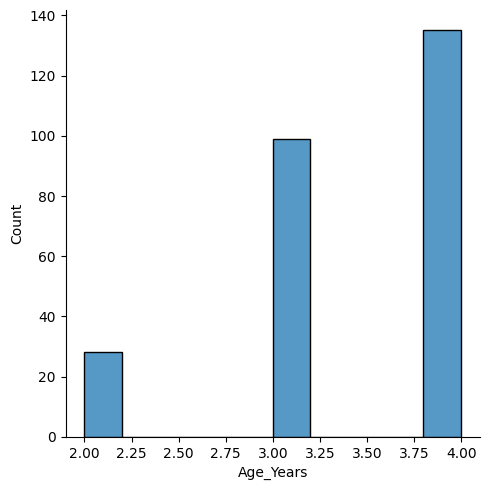

In [30]:
sns.displot(x=df_toddler['Age_Years'],)

In [31]:
df_toddler = df[(df['Age_Years'] >= 2) & (df['Age_Years'] <= 4)]

In [32]:
print(len(df_toddler))
print(df_toddler['Age_Years'].describe())

262
count    262.000000
mean       3.408397
std        0.676087
min        2.000000
25%        3.000000
50%        4.000000
75%        4.000000
max        4.000000
Name: Age_Years, dtype: float64


In [33]:
print(df_toddler.isnull().sum())

A1                                                    0
A2                                                    0
A3                                                    0
A4                                                    0
A5                                                    0
A6                                                    0
A7                                                    0
A8                                                    0
A9                                                    0
A10                                                   0
Social_Responsiveness_Scale                           0
Age_Years                                             0
Qchat_10_Score                                        3
Speech Delay/Language Disorder                        0
Learning disorder                                     0
Genetic_Disorders                                     0
Depression                                            1
Global developmental delay/intellectual disabili

In [34]:
df_toddler['Qchat_10_Score'] = df_toddler['Qchat_10_Score'].fillna(
    df_toddler['Qchat_10_Score'].median()
)

df_toddler['Social/Behavioural Issues'] = df_toddler['Social/Behavioural Issues'].fillna(
    df_toddler['Social/Behavioural Issues'].mode()[0]
)

In [35]:
features = ['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10']

X = df[features]

In [36]:
y = df['ASD_traits']   # or ASD column in your dataset

In [37]:
X = X.apply(lambda col: col.map(lambda x: 1 if x >= 1 else 0))

In [38]:
X = (X >= 1).astype(int)

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [41]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC()
}

In [42]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

Logistic Regression: 0.7657
Decision Tree: 0.8161
Random Forest: 0.8161
KNN: 0.7783
SVM: 0.8186


In [43]:
best_model = max(results, key=results.get)

print("\nBest Model:", best_model)
print("Best Accuracy:", results[best_model])


Best Model: SVM
Best Accuracy: 0.818639798488665


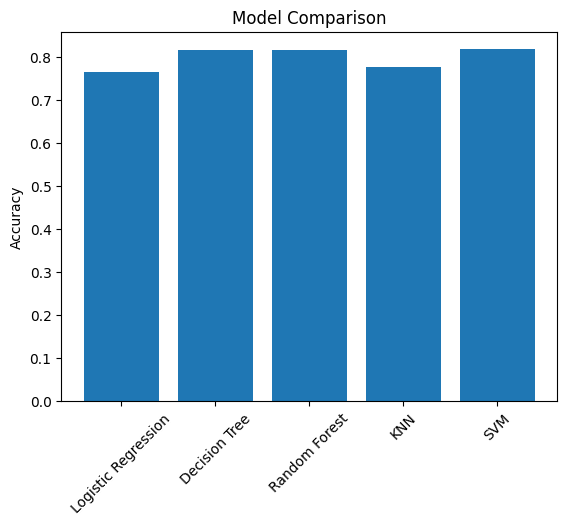

In [44]:
import matplotlib.pyplot as plt

plt.bar(results.keys(), results.values())
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.show()

In [45]:
print(df_toddler['ASD_traits'].value_counts())

ASD_traits
Yes    146
No     116
Name: count, dtype: int64


In [46]:
print(df_toddler['ASD_traits'].unique())

<StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [47]:
df['ASD_traits'] = df['ASD_traits'].map({'No': 0, 'Yes': 1})

In [48]:
print(df['ASD_traits'].value_counts())

ASD_traits
1    1074
0     911
Name: count, dtype: int64


In [49]:
df_toddler['ASD_traits'] = df_toddler['ASD_traits'].map({'No': 0, 'Yes': 1})
print(df_toddler['ASD_traits'].value_counts())

ASD_traits
1    146
0    116
Name: count, dtype: int64


In [50]:
print(X.shape, y.shape)

(1985, 10) (1985,)


In [51]:
df = df_toddler.copy()

In [52]:
x = df_toddler[['A1','A2','A3','A4','A5','A6','A7','A8','A9','A10']]
y = df_toddler['ASD_traits']

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [54]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [55]:
x_train

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10
984,1,0,1,1,0,1,1,0,1,0
593,0,0,0,0,0,0,1,0,0,1
415,0,0,0,0,0,0,0,0,0,1
1385,0,0,0,0,0,0,0,0,0,1
155,1,1,0,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...
26,1,1,0,1,1,1,1,1,0,1
1052,1,0,0,0,0,0,0,1,0,1
220,1,1,1,1,0,0,1,0,1,0
506,0,1,0,1,0,1,0,0,1,0


In [56]:
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(209, 10) (209,)
(53, 10) (53,)


In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [58]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC()
}

In [59]:
results = {}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

Logistic Regression: 0.8302
Decision Tree: 0.8113
Random Forest: 0.8491
KNN: 0.8679
SVM: 0.8302


In [60]:
from xgboost import XGBClassifier


model = XGBClassifier(
      n_estimators=500,        # more learning capacity
    max_depth=3,             # reduce overfitting
    learning_rate=0.03,      # slower, better learning
    subsample=0.8,           # row sampling
    colsample_bytree=0.8,    # feature sampling
    min_child_weight=3,      # prevents noisy splits
    gamma=0.2,               # adds regularization
    reg_alpha=0.1,           # L1 regularization
    reg_lambda=1.0,          # L2 regularization
    random_state=42,
    eval_metric='logloss'
)
model.fit(x_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [61]:
y_prob = model.predict_proba(X_test)[:, 1]

In [62]:
# evaluate chyn
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8301886792452831
              precision    recall  f1-score   support

           0       0.75      0.91      0.82        23
           1       0.92      0.77      0.84        30

    accuracy                           0.83        53
   macro avg       0.83      0.84      0.83        53
weighted avg       0.85      0.83      0.83        53



In [63]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, x, y, cv=5)
print(scores.mean())

0.873367198838897


In [64]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[21  2]
 [ 7 23]]


In [65]:
y_prob = model.predict_proba(x_test)[:, 1]
y_pred = (y_prob > 0.40).astype(int)

In [66]:
model = XGBClassifier(
    scale_pos_weight=1.2
)

In [67]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.91      0.82        23
           1       0.92      0.77      0.84        30

    accuracy                           0.83        53
   macro avg       0.83      0.84      0.83        53
weighted avg       0.85      0.83      0.83        53



In [68]:
scores = cross_val_score(model, x, y, cv=5)
print(scores.mean())

0.858200290275762


In [69]:
print(model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)


In [70]:
import numpy as np

thresholds = np.linspace(0.1, 0.9, 80)
for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    print(np.round(t, 2))

0.1
0.11
0.12
0.13
0.14
0.15
0.16
0.17
0.18
0.19
0.2
0.21
0.22
0.23
0.24
0.25
0.26
0.27
0.28
0.29
0.3
0.31
0.32
0.33
0.34
0.35
0.36
0.37
0.38
0.39
0.4
0.41
0.42
0.43
0.44
0.45
0.46
0.47
0.48
0.49
0.51
0.52
0.53
0.54
0.55
0.56
0.57
0.58
0.59
0.6
0.61
0.62
0.63
0.64
0.65
0.66
0.67
0.68
0.69
0.7
0.71
0.72
0.73
0.74
0.75
0.76
0.77
0.78
0.79
0.8
0.81
0.82
0.83
0.84
0.85
0.86
0.87
0.88
0.89
0.9


In [71]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

In [72]:
import numpy as np

optimal_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[optimal_idx]

print("Best Threshold:", best_threshold)

Best Threshold: 0.9021473526954651


In [73]:
y_pred = (y_prob >= best_threshold).astype(int)

In [74]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = (y_prob >= 0.902147).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8490566037735849
              precision    recall  f1-score   support

           0       0.74      1.00      0.85        23
           1       1.00      0.73      0.85        30

    accuracy                           0.85        53
   macro avg       0.87      0.87      0.85        53
weighted avg       0.89      0.85      0.85        53



In [75]:
y_pred = (y_prob >= 0.5).astype(int)

In [76]:
import joblib

joblib.dump(model, "asd_xgboost_model.pkl")

['asd_xgboost_model.pkl']

In [77]:
model = joblib.load("asd_xgboost_model.pkl")

In [78]:
import pickle
import numpy as np

# 1. Save the model
with open('asd_xgboost_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# 2. Clear the variable from memory to be sure
del model 

# 3. Reload it from the file
with open('asd_xgboost_model.pkl', 'rb') as f:
    reloaded_model = pickle.load(f)

# 4. Check the 'fitted' status and run a dummy prediction
try:
    # Check if the internal booster exists
    is_trained = reloaded_model.get_booster() is not None
    
    # Create a dummy input (10 zeros if you have 10 features)
    dummy_input = np.zeros((1, 10)) 
    test_pred = reloaded_model.predict(dummy_input)
    
    print(f"✅ Model Fitted: {is_trained}")
    print(f"✅ Prediction Test: {test_pred}")
    print("--- SUCCESS: This file is ready for Flask! ---")
except Exception as e:
    print(f"❌ Test Failed: {e}")

❌ Test Failed: need to call fit or load_model beforehand


In [79]:
from xgboost import XGBClassifier

# Initialize
model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    random_state=42,
    eval_metric='logloss'
)

# TRAIN (This is what was missing or failed!)
model.fit(x_train, y_train)

print("Training complete!")

Training complete!


In [80]:
# If this prints a number, the model is trained.
print(f"Number of boosting rounds: {len(model.get_booster().get_dump())}")

Number of boosting rounds: 500


In [82]:
import pickle
with open('asd_xgboost_model.pkl', 'wb') as f:
    pickle.dump(model, f)
print("✅ Trained model saved to disk!")

✅ Trained model saved to disk!
